## Costs and capacity

A result holds at the costs it was run at and at the size it was run at. These run the same
policy again where only those differ: every cost the venue charges scaled together, the
round-trip cost at which it stops making money, and the account opened at larger balances,
where the impact grows with each order and the volume a bar offers fills less of it. Then
what the run assumed, graded, and one fill's price told from its reference. The crossing of
two averages on hourly Bitcoin bars of 2024 and 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### The bars and the policy

In [2]:
PATH = pathlib.Path("../bars/binance-spot-btcusdt-1h-2024-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="spot",
                                         interval="1h", symbols=["BTCUSDT"],
                                         start="2024-01-01", end="2025-12-31")
    data.save(path=PATH)

fast = probatum.ta.ema(data.close, length=24)
slow = probatum.ta.ema(data.close, length=24 * 10)

weights = numpy.where(fast > slow, 1.0, 0.0)

### The costs scaled together

Each fee rate, the spread, the slippage and the impact multiplied by each scale, from none
to four times what `binance_spot` charges; `cost_bps` is what a round trip then paid.

In [3]:
curve = probatum.cost_curve(weights, data=data, venue="binance_spot",
                            scales=(0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0))

curve

,cost_bps,total_return_pct,sharpe,num_trades,fees,spread,slippage,impact,turnover
scale,,,,,,,,,
0.0,0.000000,57.259991,0.849585,62,0.000000,0.000000,0.000000,0.000000,62.197472
0.5,11.092076,46.721008,0.744750,62,984.979335,4.980754,96.195967,6.390484,62.091049
1.0,22.169190,36.901213,0.640005,62,1899.259097,9.617275,184.362055,12.013322,61.984535
1.5,33.230738,27.754462,0.535452,62,2747.853075,13.948888,265.031363,16.939533,61.878016
2.0,44.286701,19.221814,0.430998,62,3535.217059,17.874795,339.666687,21.318992,61.771025
3.0,66.344958,3.864444,0.223006,62,4943.654895,24.316403,469.936387,28.535234,61.556664
4.0,88.356502,-9.482666,0.016413,62,6155.859087,29.259302,579.624638,34.134169,61.340434


### Where it stops making money

`breakeven_bps` bisects the scale until the two runs on either side of a zero return pay
within a twentieth of a basis point a round trip of each other.

break-even 72.4 bps a round trip, charged at scale 1 22.2 bps


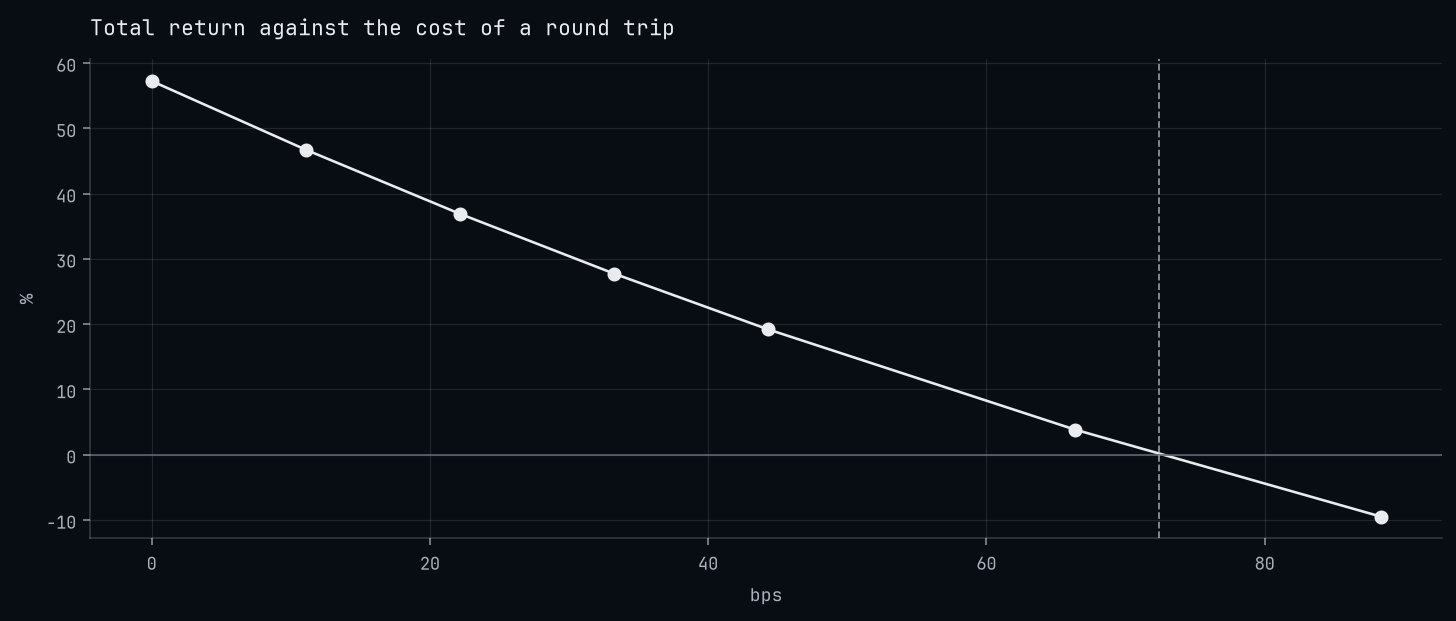

In [4]:
breakeven = probatum.breakeven_bps(weights, data=data, venue="binance_spot")
frame     = curve.to_pandas()

print(f"break-even {breakeven:.1f} bps a round trip, charged at scale 1 "
      f"{frame.loc[1.0, 'cost_bps']:.1f} bps")

axes = frame.plot(x="cost_bps", y="total_return_pct", marker="o", legend=False,
                  title="Total return against the cost of a round trip", xlabel="bps",
                  ylabel="%")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
axes.axvline(x=breakeven, color="C2", linestyle="--", linewidth=0.9)
matplotlib.pyplot.show()

### Larger accounts

The same weights from ten thousand dollars to a hundred million. A larger order pays more
impact, and each bar fills no more than a tenth of its trailing volume, so a large account
trades a slower path.

In [5]:
capacity = probatum.capacity(weights, data=data, venue="binance_spot",
                             balances=[1e4, 1e5, 1e6, 1e7, 1e8])

capacity

,total_return_pct,sharpe,impact,held,cost_bps,turnover
balance,,,,,,
10000,36.901213,0.640005,1.201332e+01,0.000000,22.169190,61.984535
100000,36.673484,0.637481,3.782513e+02,0.000000,22.436374,61.983479
1000000,35.950608,0.629461,1.184222e+04,0.000000,23.279732,61.975733
10000000,32.247294,0.588176,2.601889e+05,0.620795,24.807732,61.523620
100000000,34.272007,0.616821,2.262764e+06,0.947077,25.039887,51.333696


### What the run assumed

Every modelling choice a run makes, graded: `venue` where it does what the venue does as
far as bars show it, `simplified` where it approximates that and which way it leans, and
`optimistic` where it leaves out what venues charge or decides in the trader's favour what a
bar cannot show. A cost where the run's records measure it.

In [6]:
result = probatum.backtest(weights, data=data, venue="binance_spot")

result.assumptions.to_pandas()[["name", "value", "grade", "direction", "cost"]]

,name,value,grade,direction,cost
0,balance,"10,000 USDT",venue,None,NaN
1,fees,"maker 0.1%, taker 0.1%",venue,None,1899.259097
2,leverage,no perpetual,venue,None,NaN
3,maintenance,no perpetual,venue,None,NaN
4,liquidation,no perpetual,venue,None,NaN
5,liquidation fee,no perpetual,venue,None,NaN
6,max open orders,8 an instrument,simplified,pessimistic,NaN
7,limit fills,"through, half a step past the limit",simplified,either,NaN
8,window,24 bars,simplified,either,NaN
9,liquidity,10% of the trailing volume a bar,simplified,either,NaN


### One fill, told

A market order's price from the open it was measured from: half the estimated spread, the
slippage, the impact on the trailing volume, and the fee on its notional.

In [7]:
large = probatum.backtest(weights, data=data,
                          venue=probatum.venues.binance_spot.replace(balance=1e7))

print(result.explain(result.fills[10]))
print()
print(large.explain(large.fills[10]))

fill 10, BTCUSDT buy 0.2175 at 63,390.06, 2024-05-04 06:00
  reference        open of the bar           63,384.01
  spread           half of 0 bps, estimated      +0.00
  slippage         1.0 bps                       +6.34
  impact           sqrt, k = 0.1                 +0.47
  held in the bar  held to the bar's high        -0.76
  fee              taker 0.1% on 13,787.34       13.79

fill 10, BTCUSDT buy 58.40832 at 68,401.08, 2024-04-06 21:00
  reference        open of the bar                 68,390.00
  spread           half of 0 bps, estimated            +0.00
  slippage         1.0 bps                             +6.84
  impact           sqrt, k = 0.1                       +4.24
  held in the bar  the bar's high was not reached      +0.00
  fee              taker 0.1% on 3,995,191.97       3,995.19
